
# UNIVERSIDAD AUTÓNOMA DEL ESTADO DE MÉXICO

## Centro Universitario UAEM Zumpango

**Asignatura:** Investigación de Operaciones

**Actividad:** Ejercicio 3. Ruta más corta mediante el algoritmo de Dijkstra

**Tipo de actividad:** Individual

**Alumno:** Alfredo Adair Herrera Rodríguez

**Fecha:** 26/11/2026



# 1. Planteamiento del problema

El problema consiste en determinar la ruta de menor costo entre el nodo 1 y el nodo 9 de una red dirigida y ponderada.

La red está formada por nueve nodos conectados mediante arcos que representan las posibles rutas entre ellos. Cada arco tiene un valor numérico que representa su costo.

El objetivo es encontrar el recorrido que permita llegar desde el nodo de origen (1) hasta el nodo de destino (9), minimizando la suma de los costos de los arcos utilizados.

Para resolver el problema se utilizará el algoritmo de Dijkstra y se formulará un modelo de programación lineal que permita representar matemáticamente la ruta más corta.



# 2. Identificación de nodos y arcos

La red está integrada por nueve nodos:

V = {1, 2, 3, 4, 5, 6, 7, 8, 9}

Los nodos 1 y 9 representan el origen y el destino, respectivamente.

Los arcos dirigidos y sus costos son:

| Arco | Costo |
|---|---:|
| 1 → 2 | 4 |
| 1 → 3 | 2 |
| 2 → 3 | 2 |
| 3 → 2 | 4 |
| 2 → 4 | 7 |
| 3 → 4 | 9 |
| 3 → 5 | 6 |
| 5 → 4 | 2 |
| 4 → 6 | 1 |
| 4 → 7 | 5 |
| 5 → 6 | 4 |
| 5 → 7 | 3 |
| 5 → 8 | 2 |
| 6 → 7 | 1 |
| 7 → 6 | 4 |
| 6 → 9 | 5 |
| 7 → 9 | 5 |
| 7 → 8 | 3 |
| 8 → 7 | 2 |
| 8 → 9 | 6 |



# 3. Preparación del entorno

En este apartado se definirán los nodos y arcos de la red mediante Python.

Se utilizarán estructuras de datos para almacenar las conexiones y sus respectivos costos. Posteriormente, esta información será utilizada por el algoritmo de Dijkstra.


In [3]:

# Importar las bibliotecas necesarias
import heapq
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Definir los arcos dirigidos y sus costos
arcos = [
    (1, 2, 4),
    (1, 3, 2),
    (2, 3, 2),
    (3, 2, 4),
    (2, 4, 7),
    (3, 4, 9),
    (3, 5, 6),
    (5, 4, 2),
    (4, 6, 1),
    (4, 7, 5),
    (5, 6, 4),
    (5, 7, 3),
    (5, 8, 2),
    (6, 7, 1),
    (7, 6, 4),
    (6, 9, 5),
    (7, 9, 5),
    (7, 8, 3),
    (8, 7, 2),
    (8, 9, 6)
]

# Crear la lista de nodos
nodos = list(range(1, 10))

# Mostrar los datos
print("Nodos de la red:", nodos)
print("Cantidad de nodos:", len(nodos))
print("Cantidad de arcos:", len(arcos))


Nodos de la red: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Cantidad de nodos: 9
Cantidad de arcos: 20



# 4. Función objetivo

La función objetivo consiste en minimizar el costo total del recorrido desde el nodo 1 hasta el nodo 9.

Se define la variable de decisión:

xij = 1, si se utiliza el arco que conecta el nodo i con el nodo j.

xij = 0, si no se utiliza dicho arco.

La función objetivo es:

Minimizar Z =

4x12 + 2x13 + 2x23 + 4x32 + 7x24 + 9x34
+ 6x35 + 2x54 + x46 + 5x47 + 4x56
+ 3x57 + 2x58 + 4x76 + x67 + 5x69
+ 5x79 + 2x87 + 3x78 + 6x89

Donde Z representa el costo total de la ruta seleccionada.



# 5. Restricciones del modelo

Las restricciones representan la conservación del flujo dentro de la red.

Nodo 1 (origen):

x12 + x13 = 1

Nodo 2:

x23 + x24 - x12 - x32 = 0

Nodo 3:

x32 + x34 + x35 - x13 - x23 = 0

Nodo 4:

x46 + x47 - x24 - x34 - x54 = 0

Nodo 5:

x54 + x56 + x57 + x58 - x35 = 0

Nodo 6:

x67 + x69 - x46 - x56 - x76 = 0

Nodo 7:

x76 + x79 + x78 - x47 - x57 - x67 - x87 = 0

Nodo 8:

x87 + x89 - x58 - x78 = 0

Nodo 9 (destino):

x69 + x79 + x89 = 1

Restricción de las variables:

xij ∈ {0,1}

Cada variable es binaria, por lo que solamente puede tomar los valores 0 o 1.



# 6. Modelo de programación lineal (PL)

El modelo de programación lineal busca minimizar el costo total de transporte entre los nodos 1 y 9.

Se define formalmente como:

Minimizar:

Z = Σ cij * xij

Sujeto a:

1. El nodo de origen debe enviar una unidad de flujo.
2. En los nodos intermedios, el flujo que entra debe ser igual al flujo que sale.
3. El nodo de destino debe recibir una unidad de flujo.
4. Todas las variables de decisión deben ser binarias.

Donde:

cij = costo del arco que conecta los nodos i y j.

xij = variable binaria que indica si el arco es utilizado.

La solución debe representar un recorrido válido desde el nodo 1 hasta el nodo 9 con el menor costo posible.



# 7. Método seleccionado: Algoritmo de Dijkstra

Para resolver el problema se seleccionó el algoritmo de Dijkstra.

Este algoritmo permite encontrar las rutas de menor costo desde un nodo de origen hacia los demás nodos de una red dirigida o no dirigida, siempre que los costos de sus arcos sean no negativos.

Su funcionamiento consiste en:

1. Asignar distancia cero al nodo de origen.
2. Asignar distancia infinita a los demás nodos.
3. Seleccionar el nodo no visitado con la menor distancia acumulada.
4. Revisar sus conexiones y actualizar las distancias cuando se encuentre un costo menor.
5. Marcar el nodo como visitado.
6. Repetir el procedimiento hasta determinar la distancia mínima al destino.

En este ejercicio, el nodo de origen es el 1 y el nodo de destino es el 9.



# 8. Desarrollo del algoritmo de Dijkstra

En este apartado se implementará el algoritmo de Dijkstra utilizando Python.

El programa calculará las distancias mínimas desde el nodo 1, registrará los nodos visitados y almacenará los predecesores para reconstruir la ruta hasta el nodo 9.

También se generará una tabla con las iteraciones del algoritmo para observar cómo se actualizan las distancias.


In [4]:

# Crear la lista de adyacencia
grafo = {nodo: [] for nodo in nodos}

for origen, destino, costo in arcos:
    grafo[origen].append((destino, costo))

# Implementar el algoritmo de Dijkstra
def dijkstra(grafo, origen, destino):
    distancias = {nodo: float('inf') for nodo in grafo}
    anteriores = {nodo: None for nodo in grafo}
    visitados = set()
    cola = [(0, origen)]
    historial = []

    distancias[origen] = 0

    while cola:
        distancia_actual, nodo_actual = heapq.heappop(cola)

        if nodo_actual in visitados:
            continue

        visitados.add(nodo_actual)

        # Revisar las conexiones del nodo actual
        for vecino, costo in grafo[nodo_actual]:
            nueva_distancia = distancia_actual + costo

            if nueva_distancia < distancias[vecino]:
                distancias[vecino] = nueva_distancia
                anteriores[vecino] = nodo_actual
                heapq.heappush(cola, (nueva_distancia, vecino))

        # Guardar el estado de las distancias
        historial.append({
            "Nodo visitado": nodo_actual,
            **distancias.copy()
        })

    # Reconstruir la ruta más corta
    ruta = []
    actual = destino

    while actual is not None:
        ruta.append(actual)
        actual = anteriores[actual]

    ruta.reverse()

    return distancias, anteriores, ruta, historial


# Ejecutar el algoritmo
distancias, anteriores, ruta, historial = dijkstra(
    grafo, 1, 9
)

print("Ruta encontrada:", ruta)
print("Costo mínimo:", distancias[9])


Ruta encontrada: [1, 3, 5, 8, 9]
Costo mínimo: 16



# 9. Tabla de iteraciones

Se presenta el registro de las iteraciones realizadas por el algoritmo de Dijkstra.

La tabla muestra el nodo que se selecciona en cada paso y las distancias acumuladas hacia los demás nodos.

Las distancias se actualizan cuando se encuentra un recorrido de menor costo.


In [5]:

# Convertir el historial en una tabla
tabla_iteraciones = pd.DataFrame(historial)

# Mostrar las distancias de forma ordenada
tabla_iteraciones = tabla_iteraciones[
    ["Nodo visitado"] + nodos
]

print("Tabla de iteraciones de Dijkstra:")
display(tabla_iteraciones.fillna("∞"))


Tabla de iteraciones de Dijkstra:


,Nodo visitado,1,2,3,4,5,6,7,8,9
0,1,0,4,2,inf,inf,inf,inf,inf,inf
1,3,0,4,2,11.0,8.0,inf,inf,inf,inf
2,2,0,4,2,11.0,8.0,inf,inf,inf,inf
3,5,0,4,2,10.0,8.0,12.0,11.0,10.0,inf
4,4,0,4,2,10.0,8.0,11.0,11.0,10.0,inf
5,8,0,4,2,10.0,8.0,11.0,11.0,10.0,16.0
6,6,0,4,2,10.0,8.0,11.0,11.0,10.0,16.0
7,7,0,4,2,10.0,8.0,11.0,11.0,10.0,16.0
8,9,0,4,2,10.0,8.0,11.0,11.0,10.0,16.0



# 10. Representación gráfica de la red

Se realizará una representación gráfica de la red para visualizar los nueve nodos, sus conexiones y los costos correspondientes.

La ruta encontrada mediante Dijkstra se resaltará para distinguirla de las demás conexiones.


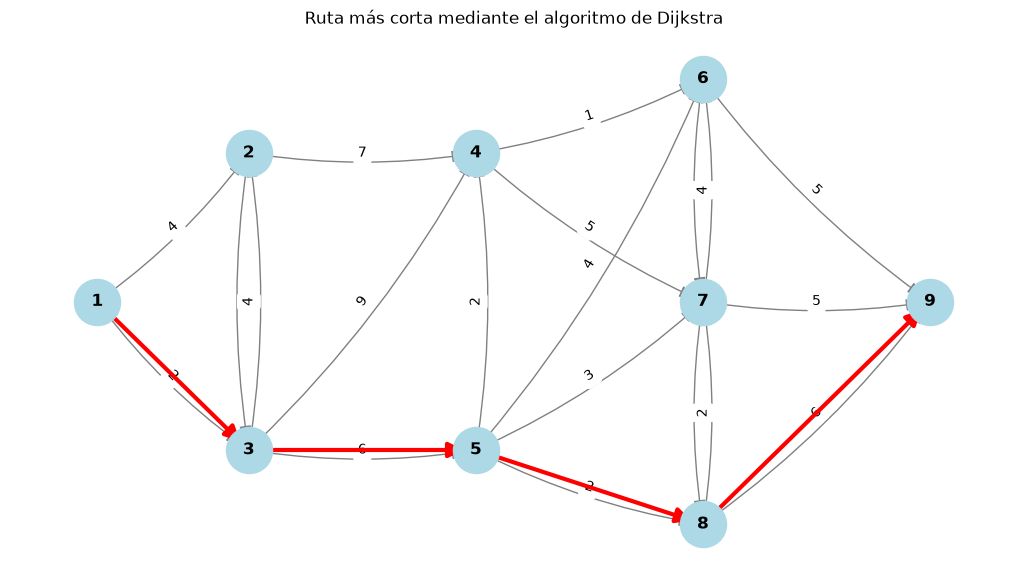

In [6]:

# Crear el grafo dirigido para su representación
G = nx.DiGraph()

for origen, destino, costo in arcos:
    G.add_edge(origen, destino, weight=costo)

# Definir posiciones de los nodos
posiciones = {
    1: (0, 1),
    2: (1, 2),
    3: (1, 0),
    4: (2.5, 2),
    5: (2.5, 0),
    6: (4, 2.5),
    7: (4, 1),
    8: (4, -0.5),
    9: (5.5, 1)
}

# Crear la figura
plt.figure(figsize=(13, 7))

# Dibujar los nodos y las conexiones
nx.draw_networkx_nodes(
    G, posiciones,
    node_size=1100,
    node_color="lightblue"
)

nx.draw_networkx_labels(
    G, posiciones,
    font_size=12,
    font_weight="bold"
)

nx.draw_networkx_edges(
    G, posiciones,
    edge_color="gray",
    arrows=True,
    arrowsize=18,
    connectionstyle="arc3,rad=0.08"
)

# Mostrar los costos de los arcos
etiquetas = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G, posiciones,
    edge_labels=etiquetas,
    font_size=10
)

# Resaltar una de las rutas óptimas
ruta_aristas = list(zip(ruta, ruta[1:]))

nx.draw_networkx_edges(
    G, posiciones,
    edgelist=ruta_aristas,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=22
)

plt.title("Ruta más corta mediante el algoritmo de Dijkstra")
plt.axis("off")
plt.show()



# 11. Identificación de las rutas óptimas

Al analizar los resultados se observa que existen tres recorridos diferentes que alcanzan el mismo costo mínimo.

Las rutas son:

Ruta 1:

1 → 3 → 5 → 4 → 6 → 9

Costo: 2 + 6 + 2 + 1 + 5 = 16

Ruta 2:

1 → 3 → 5 → 7 → 9

Costo: 2 + 6 + 3 + 5 = 16

Ruta 3:

1 → 3 → 5 → 8 → 9

Costo: 2 + 6 + 2 + 6 = 16

Por lo tanto, existen tres soluciones óptimas con un costo mínimo de 16 unidades.


In [7]:

# Definir las tres rutas óptimas encontradas
rutas_optimas = [
    [1, 3, 5, 4, 6, 9],
    [1, 3, 5, 7, 9],
    [1, 3, 5, 8, 9]
]

# Calcular el costo de cada ruta
for i, camino in enumerate(rutas_optimas, start=1):
    costo_total = sum(
        G[u][v]["weight"]
        for u, v in zip(camino, camino[1:])
    )

    print(f"Ruta {i}: {camino}")
    print(f"Costo total: {costo_total}")
    print("-" * 40)


Ruta 1: [1, 3, 5, 4, 6, 9]
Costo total: 16
----------------------------------------
Ruta 2: [1, 3, 5, 7, 9]
Costo total: 16
----------------------------------------
Ruta 3: [1, 3, 5, 8, 9]
Costo total: 16
----------------------------------------



# 12. Resultados de las variables de decisión

Las variables de decisión indican si un arco forma parte de la ruta seleccionada.

Si el arco se utiliza, su variable toma el valor de 1. Si no se utiliza, toma el valor de 0.

Tomando como solución la primera ruta óptima encontrada por Dijkstra:

1 → 3 → 5 → 4 → 6 → 9

Los valores de las variables se determinarán de acuerdo con los arcos utilizados en este recorrido.


In [8]:

# Obtener los arcos que forman parte de la ruta seleccionada
arcos_seleccionados = set(zip(ruta, ruta[1:]))

# Crear las variables binarias
variables = {}

for origen, destino, costo in arcos:
    nombre = f"x{origen}{destino}"

    if (origen, destino) in arcos_seleccionados:
        variables[nombre] = 1
    else:
        variables[nombre] = 0

# Crear una tabla de resultados
tabla_variables = pd.DataFrame(
    list(variables.items()),
    columns=["Variable", "Valor"]
)

print("Resultados de las variables de decisión:")
display(tabla_variables)


Resultados de las variables de decisión:


,Variable,Valor
0,x12,0
1,x13,1
2,x23,0
3,x32,0
4,x24,0
5,x34,0
6,x35,1
7,x54,0
8,x46,0
9,x47,0



# 13. Sustitución de las variables en la función objetivo

Para obtener el costo total se sustituyen los valores de las variables de decisión en la función objetivo.

La ruta seleccionada es:

1 → 3 → 5 → 4 → 6 → 9

Por lo tanto:

x13 = 1
x35 = 1
x54 = 1
x46 = 1
x69 = 1

Las demás variables toman el valor de cero.

Sustituyendo:

Z = 4(0) + 2(1) + 2(0) + 4(0) + 7(0)
+ 9(0) + 6(1) + 2(1) + 1(1) + 5(0)
+ 4(0) + 3(0) + 2(0) + 4(0) + 1(0)
+ 5(1) + 5(0) + 2(0) + 3(0) + 6(0)

Z = 2 + 6 + 2 + 1 + 5

Z = 16

El costo mínimo de la ruta es de 16 unidades.


In [9]:

# Calcular el costo mediante la función objetivo
costo_objetivo = sum(
    costo * variables[f"x{origen}{destino}"]
    for origen, destino, costo in arcos
)

print("Sustitución de variables en la función objetivo:")

for origen, destino, costo in arcos:
    nombre = f"x{origen}{destino}"
    valor = variables[nombre]

    print(f"{costo}({valor})", end=" + ")

print("\n\nCosto mínimo Z =", costo_objetivo)


Sustitución de variables en la función objetivo:
4(0) + 2(1) + 2(0) + 4(0) + 7(0) + 9(0) + 6(1) + 2(0) + 1(0) + 5(0) + 4(0) + 3(0) + 2(1) + 1(0) + 4(0) + 5(0) + 5(0) + 3(0) + 2(0) + 6(1) + 

Costo mínimo Z = 16



# 14. Conclusión

Mediante el desarrollo de esta actividad se logró resolver el problema de la ruta más corta entre los nodos 1 y 9 utilizando el algoritmo de Dijkstra.

A través de Python se representó la red, se calcularon las distancias mínimas y se identificaron los recorridos que permiten llegar al destino con el menor costo.

Los resultados demostraron que existen tres rutas óptimas diferentes, todas con un costo mínimo de 16 unidades.

También se formuló el modelo de programación lineal, identificando la función objetivo, las restricciones de conservación de flujo y las variables binarias de decisión.

Finalmente, se comprobó que la sustitución de las variables en la función objetivo produce el mismo resultado obtenido mediante el algoritmo de Dijkstra.

Esta actividad permitió comprender cómo los algoritmos y los modelos matemáticos pueden utilizarse para resolver problemas de optimización de rutas.



# 15. Verificación general de resultados

En este apartado se presentan los resultados generales obtenidos durante la ejecución del programa.

Se verificará que:

- La ruta inicia en el nodo 1.
- La ruta termina en el nodo 9.
- Los arcos utilizados pertenecen a la red original.
- El costo calculado coincide con la función objetivo.
- Las tres rutas identificadas tienen el mismo costo mínimo.


In [10]:

# Verificar los resultados obtenidos
print("========== RESUMEN DE RESULTADOS ==========")
print("Nodo de origen:", 1)
print("Nodo de destino:", 9)
print("Ruta obtenida por Dijkstra:", ruta)
print("Costo mínimo:", distancias[9])
print("Número de rutas óptimas:", len(rutas_optimas))

# Comprobar el costo de las tres rutas
costos = []

for camino in rutas_optimas:
    costo = sum(
        G[u][v]["weight"]
        for u, v in zip(camino, camino[1:])
    )
    costos.append(costo)

print("Costos de las rutas óptimas:", costos)

assert all(c == 16 for c in costos)
assert costo_objetivo == distancias[9]

print("\nVERIFICACIÓN CORRECTA")


========== RESUMEN DE RESULTADOS ==========
Nodo de origen: 1
Nodo de destino: 9
Ruta obtenida por Dijkstra: [1, 3, 5, 8, 9]
Costo mínimo: 16
Número de rutas óptimas: 3
Costos de las rutas óptimas: [16, 16, 16]

VERIFICACIÓN CORRECTA
